# Appendix A: Export and Validate


In [1]:
import msmu as mm
import mudata as md

## Load the existing provenance history


In [2]:
mdata = md.read_h5mu("MSV000089280.h5mu")

## Export requirements and a script with verification

`mm.pv.to_env()` writes the recorded Python package requirements to `requirements.txt`. `mm.pv.to_script(..., verify=True)` writes `script.py` with checks for the environment, recorded inputs and output hashes when the script is run.

Exporting these files does not execute the workflow or establish successful replay. Run the generated script separately with its referenced upstream inputs available. The requirements capture version pins, but do not restore native libraries, thread settings or uncommitted source edits.


In [3]:
mm.pv.to_env(mdata, "requirements.txt")
mm.pv.to_script(mdata, "script.py", verify=True)

## Recreate the environment and run the script (e.g., on Debian)

On Debian, run from the directory containing `requirements.txt`, `script.py` and the original `MSV000089280/` input folder. Create the recorded environment with [uv](https://docs.astral.sh/uv/guides/scripts/), append the checkpoint save to `script.py`, and run it:

```bash
uv venv --python 3.13.5 .venv-replay
uv pip sync --python .venv-replay/bin/python requirements.txt
printf '\nmdata.write_h5mu("MSV000089280_debian.h5mu")\n' >> script.py
uv run --no-project --python .venv-replay/bin/python python script.py
```

After successful completion, copy `MSV000089280_debian.h5mu` to this tutorial directory on macOS for the comparison below.


## Compare macOS and Debian processing endpoints

Requires the separately prepared `MSV000089280_debian.h5mu` in this directory.


In [4]:
import msmu as mm
import mudata as md
import numpy as np
import pandas as pd

mm.pv.set_options(hashing=False)

In [5]:
mdata_mac = md.read_h5mu("MSV000089280.h5mu")
mdata_deb = md.read_h5mu("MSV000089280_debian.h5mu")

### Identification-set agreement


In [6]:
sets = []
for mdata in (mdata_mac, mdata_deb):
    peptide, protein = mdata.mod["peptide"], mdata.mod["protein"]
    proteins = set(protein.var_names)
    edges = {(name, group)
             for name, groups in peptide.var["protein_group"].dropna().items()
             for group in groups.split(";") if group in proteins}
    sets.append([set(peptide.var_names), proteins, edges])
identification_shared = np.array([len(left & right) for left, right in zip(*sets)])
identification_unions = np.array([len(left | right) for left, right in zip(*sets)])

pd.DataFrame({
    "Shared": identification_shared,
    "Union": identification_unions,
    "Jaccard": identification_shared / identification_unions,
}, index=["Peptide nodes", "Protein nodes", "Peptide-protein edges"])

,Shared,Union,Jaccard
Peptide nodes,3910,3910,1.0
Protein nodes,933,933,1.0
Peptide-protein edges,3973,3973,1.0


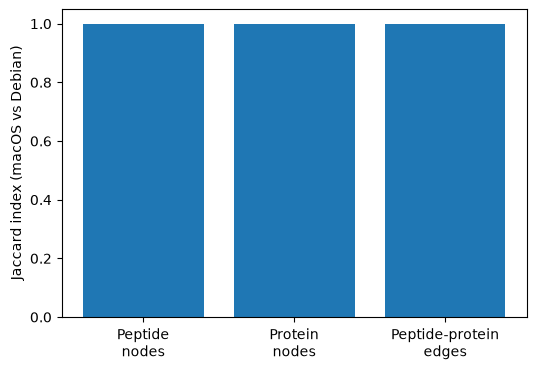

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Peptide\nnodes", "Protein\nnodes", "Peptide-protein\nedges"], identification_shared / identification_unions)
ax.set_ylabel("Jaccard index (macOS vs Debian)")
plt.show()

### Protein identification q-values


In [8]:
q = pd.concat([
    mdata_mac.mod["protein"].var["q_value"].rename("macOS"),
    mdata_deb.mod["protein"].var["q_value"].rename("Debian"),
], axis=1, join="inner").dropna()

protein_q_values = -np.log10(q.clip(lower=np.finfo(float).tiny)).to_numpy()
protein_q_values = np.asarray(protein_q_values, dtype=float)
delta = protein_q_values[:, 1] - protein_q_values[:, 0]

pd.DataFrame({
    "Pairs": [len(protein_q_values)],
    "RMSD": [np.sqrt(np.mean(delta**2))],
    "Max |Δ|": [np.abs(delta).max()],
})

,Pairs,RMSD,Max |Δ|
0,933,0.0,0.0


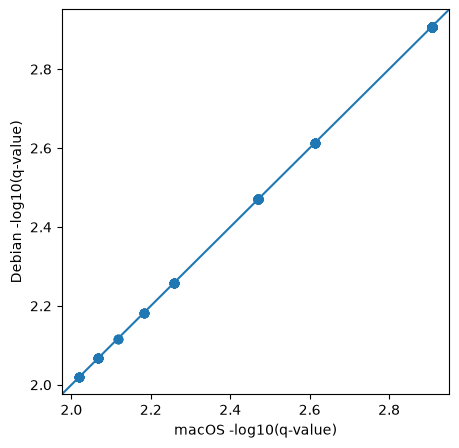

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(protein_q_values[:, 0], protein_q_values[:, 1])
limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(limits, limits)
ax.set(xlim=limits, ylim=limits, xlabel="macOS -log10(q-value)", ylabel="Debian -log10(q-value)")
plt.show()

### Observed protein intensities


In [10]:
left = mdata_mac.mod["protein"].to_df()
right = mdata_deb.mod["protein"].to_df()

samples = left.index.intersection(right.index, sort=False)
proteins = left.columns.intersection(right.columns, sort=False)
x = left.loc[samples, proteins].to_numpy().ravel()
y = right.loc[samples, proteins].to_numpy().ravel()

observed = np.isfinite(x) & np.isfinite(y)
missing_mismatch = np.count_nonzero(np.isnan(x) != np.isnan(y))
protein_intensities = np.asarray(np.column_stack([x[observed], y[observed]]), dtype=float)
delta = protein_intensities[:, 1] - protein_intensities[:, 0]

pd.DataFrame({
    "Pairs": [len(protein_intensities)],
    "RMSD": [np.sqrt(np.mean(delta**2))],
    "Max |Δ|": [np.abs(delta).max()],
    "Missing mismatches": [missing_mismatch],
})

,Pairs,RMSD,Max |Δ|,Missing mismatches
0,23238,2.018327e-17,1.776357e-15,0


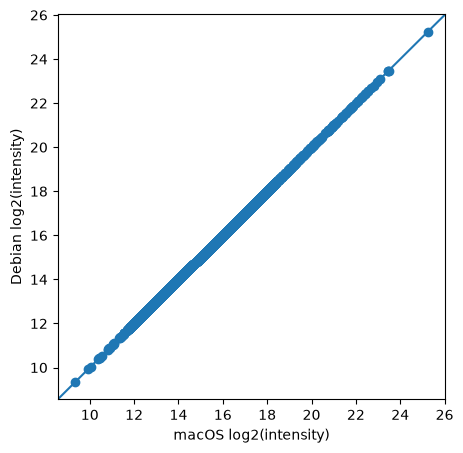

In [11]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(protein_intensities[:, 0], protein_intensities[:, 1])
limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(limits, limits)
ax.set(xlim=limits, ylim=limits, xlabel="macOS log2(intensity)", ylabel="Debian log2(intensity)")
plt.show()

### Differential-expression agreement


In [12]:
de_settings = dict(modality="protein", category="factor value[condition]",
                   ctrl="C10", expr="SVEC", stat_method="limma", p_adjust="bh",
                   min_pct=0.0, log_transformed=True, layer=None)

de_mac = mm.tl.run_de(mdata_mac, **de_settings)
de_deb = mm.tl.run_de(mdata_deb, **de_settings)

q_mac = pd.Series(de_mac.q_value, index=de_mac.features, name="macOS")
q_deb = pd.Series(de_deb.q_value, index=de_deb.features, name="Debian")

q_pairs = pd.concat([q_mac, q_deb], axis=1, join="inner").dropna()
de_q_values = -np.log10(q_pairs.clip(lower=np.finfo(float).tiny)).to_numpy()
de_q_values = np.asarray(de_q_values, dtype=float)

de_thresholds = np.array([0.10, 0.05, 0.01])
de_shared, de_unions = [], []
for threshold in de_thresholds:
    called_mac = set(q_mac.index[q_mac < threshold])
    called_deb = set(q_deb.index[q_deb < threshold])
    de_shared.append(len(called_mac & called_deb))
    de_unions.append(len(called_mac | called_deb))
de_shared, de_unions = np.array(de_shared), np.array(de_unions)

pd.DataFrame({"q threshold": de_thresholds, "Shared": de_shared, "Union": de_unions})

WARNING - mm.tl.run_de: the default DE engine is now 'limma' (previously a permutation test). Pass stat_method explicitly to choose an engine. This notice will be removed in a future release.


,q threshold,Shared,Union
0,0.10,274,274
1,0.05,248,248
2,0.01,187,187


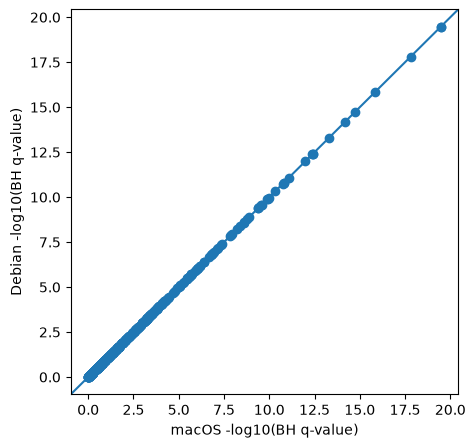

In [13]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(de_q_values[:, 0], de_q_values[:, 1])
limits = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(limits, limits)
ax.set(xlim=limits, ylim=limits, xlabel="macOS -log10(BH q-value)", ylabel="Debian -log10(BH q-value)")
plt.show()